# JS10 Lab 4: Klasifikasi Siang dan Malam dengan ANN

Jobsheet 10, Lab 4. Citra siang dan malam tidak diberi langsung ke ANN. Tiap citra diringkas dulu menjadi vektor fitur HOG (Histogram of Oriented Gradients), lalu vektor itu yang menjadi input jaringan.

Dataset memakai citra yang sama dengan JS06 Lab 5, jadi dibaca langsung dari `../JS06/dataset/images` dan tidak disalin ulang ke folder ini: 120 citra latih dan 80 citra uji untuk masing-masing kelas.

## Langkah 1 - Import Library

In [1]:
from pathlib import Path
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(0)

## Langkah 2 - Load Dataset

In [2]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "../JS06/dataset/images/training/"
test_dir  = "../JS06/dataset/images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(len(train_img), len(test_img))

240 160


## Langkah 2 - Pra Pengolahan

In [3]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

## Langkah 3 - Ekstraksi Fitur

In [4]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print(X_train_feat.shape, X_test_feat.shape)

(240, 34596) (160, 34596)


Satu citra 256x256 menghasilkan 34.596 angka HOG. ANN menerima vektor sepanjang itu, bukan pikselnya.

## Langkah 4 - Standardisasi Fitur

In [5]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

## Langkah 5 - Buat Data Latih dan Validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# Convert label ke numpy array
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

Data uji disisihkan dari awal dan tidak pernah dilihat model selama pelatihan. Data validasi dipakai untuk memantau apakah model mulai menghafal data latih.

## Langkah 6 - Buat Model ANN

Arsitektur model yang digunakan adalah,

* Input Layer
* Hidden Layer 1 - 128 Nodes - ReLU
* Hidden Layer 2 - 64 Nodes - ReLU
* Output Layer - 1 Node - Sigmoid

Catatan: deskripsi modul menyebut output 2 node sigmoid, tetapi kode di bawah memakai 1 node sigmoid karena targetnya biner. Kode yang dijalankan adalah yang satu node.

In [7]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

Layer pertama sudah memegang sekitar 4,4 juta parameter (34.596 x 128) karena inputnya vektor HOG sepanjang 34.596. Jumlah parameter inilah yang menunjukkan bahwa kompleksitas model sebagian besar berada di koneksi input ke hidden layer.

## Langkah 7 - Latih Model

In [8]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose = 0
)

## Langkah 8 - Evaluasi Model dengan Data Test

In [9]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose = 0)
print("Akurasi Test:", test_acc)

Akurasi Test: 0.9375


## Langkah 9 - Buat Laporan Performansi Model

In [10]:
y_pred_prob = model.predict(X_test_scaled, verbose = 0)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['night', 'day']))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

       night       0.90      0.99      0.94        80
         day       0.99      0.89      0.93        80

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160

[[79  1]
 [ 9 71]]


## Langkah 10 - Visualisasi Proses Training

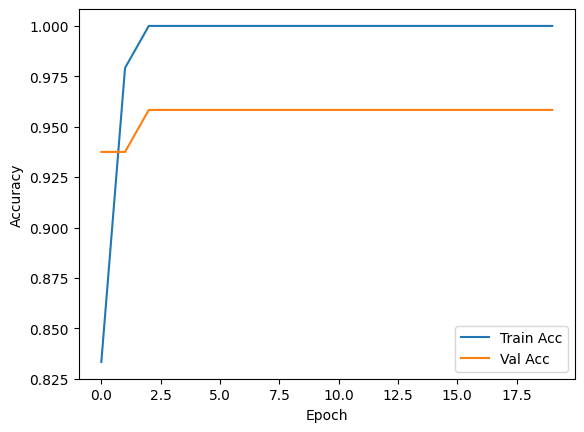

In [11]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [12]:
acc = history.history['accuracy']
val = history.history['val_accuracy']
print(f"Train Acc  akhir: {acc[-1]:.4f} | terbaik: {max(acc):.4f}")
print(f"Val Acc    akhir: {val[-1]:.4f} | terbaik: {max(val):.4f}")

Train Acc  akhir: 1.0000 | terbaik: 1.0000
Val Acc    akhir: 0.9583 | terbaik: 0.9583


Angka di atas memberi dua hal yang tidak terlihat dari grafik saja: akurasi latih menyentuh 1.0000, sedangkan validasi berhenti di 0.9583 dan data uji 0.9375. Model sudah menghafal data latih, dan selisih sekitar 4% terhadap data validasi adalah tanda overfitting ringan.

Penyebabnya masuk akal: 240 citra latih untuk 4,5 juta parameter. Overfitting bisa ditekan dengan menambah data (augmentasi flip dan perubahan kecerahan), mengecilkan hidden layer, atau menambah dropout. Untuk citra, CNN pada JS11 juga jauh lebih efisien parameter karena tidak perlu vektor HOG sepanjang 34.596.

Di sisi lain, 0.9375 pada data uji membuktikan fitur HOG sudah memisahkan siang dan malam dengan baik. Kesalahan yang tersisa ada pada citra senja atau malam yang masih terang, yang batas kelasnya memang kabur.

## Langkah 11 - Simpan Model

In [13]:
model.save('day_night_classifier_model.keras')

Format `.keras` dipakai karena Keras 3 tidak lagi menyarankan `.h5` untuk model baru.